# Stage 2 — Data Quality Investigation

**Purpose:** decide how to clean the Telco Customer Churn dataset, using evidence rather than convention.

Four issues need a decision. For each one this notebook shows the evidence, compares the reasonable
treatments, and records a decision with its limitations.

| # | Issue | Question |
|---|---|---|
| 1 | `TotalCharges` has 11 blank values | Drop the rows, impute, or set to zero? |
| 2 | `"No internet service"` appears as a third category | Is it redundant, or does it carry signal? |
| 3 | `SeniorCitizen` is `0/1` while other binaries are `Yes/No` | Does this actually cause a problem? |
| 4 | `TotalCharges` ≈ `tenure × MonthlyCharges` | How collinear, and does it matter? |

The decisions reached here are implemented in `src/clean_data.py` and documented in
`docs/data_dictionary.md`. **This notebook reads the raw file and never modifies it.**

---

## Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the project root whether this runs from notebooks/ or from the repo root.
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
RAW_PATH = ROOT / "data" / "raw" / "telco_customer_churn.csv"

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Plot styling: recessive grid and axes so the data is the loudest thing on the chart.
BLUE, INK, MUTED = "#2a78d6", "#0b0b0b", "#8a8a85"
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "grid.color": "#e5e5e2", "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
})

print("Reading:", RAW_PATH.relative_to(ROOT))

Reading: data/raw/telco_customer_churn.csv


### Naming convention used in this notebook

Dataframes are named for **what they contain**, never `df`. There are four, and mixing them up is
the easiest mistake to make here:

| Name | Contents | Rows |
|---|---|---|
| `raw` | the raw CSV, every column as text | 7,043 |
| `raw_num` | `raw` with the three charge/tenure columns parsed as numbers (11 `NaN`s) | 7,043 |
| `charges` | `raw_num` minus the 11 unparseable rows — **a subset for the Issue 4 maths only** | 7,032 |
| `clean` | the cleaned output, loaded at the end to verify | 7,043 |

### Why we read everything as text

If we let pandas infer types, it quietly decides `TotalCharges` is a **string** column
(because 11 values are blank) and tells us nothing. Reading as text and then *forcing*
the conversion ourselves makes the defect visible and countable.

In [2]:
raw = pd.read_csv(RAW_PATH, dtype=str)
print(f"{raw.shape[0]} rows x {raw.shape[1]} columns")

# A numeric working copy. errors="coerce" turns anything unparseable into NaN
# instead of raising -- that is how we *find* the bad values rather than crash on them.
raw_num = raw.copy()
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    raw_num[col] = pd.to_numeric(raw_num[col], errors="coerce")

# Helper used throughout: churn rate as a percentage.
def churn_rate(s):
    return (s == "Yes").mean() * 100

baseline = churn_rate(raw["Churn"])
print(f"Baseline churn rate: {baseline:.2f}%  "
      f"({(raw['Churn'] == 'Yes').sum()} churned / {(raw['Churn'] == 'No').sum()} retained)")

7043 rows x 21 columns
Baseline churn rate: 26.54%  (1869 churned / 5174 retained)


---
# Issue 1 — The 11 rows with blank `TotalCharges`

The instinct is to drop them or fill them with the median. Let's look at them first.

In [3]:
bad = raw_num[raw_num["TotalCharges"].isna()]
bad[["customerID", "tenure", "MonthlyCharges", "TotalCharges",
     "Contract", "InternetService", "PhoneService", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Contract,InternetService,PhoneService,Churn
488,4472-LVYGI,0,52.55,NaN,Two year,DSL,No,No
753,3115-CZMZD,0,20.25,NaN,Two year,No,Yes,No
936,5709-LVOEQ,0,80.85,NaN,Two year,DSL,Yes,No
1082,4367-NUYAO,0,25.75,NaN,Two year,No,Yes,No
1340,1371-DWPAZ,0,56.05,NaN,Two year,DSL,No,No
3331,7644-OMVMY,0,19.85,NaN,Two year,No,Yes,No
3826,3213-VVOLG,0,25.35,NaN,Two year,No,Yes,No
4380,2520-SGTTA,0,20.00,NaN,Two year,No,Yes,No
5218,2923-ARZLG,0,19.70,NaN,One year,No,Yes,No
6670,4075-WKNIU,0,73.35,NaN,Two year,DSL,Yes,No


Three things jump out: every one has **`tenure = 0`**, every one has **`Churn = No`**,
and almost all are on **two-year contracts**.

First, is "blank `TotalCharges`" the same problem as "`tenure = 0`", or two overlapping problems?

In [4]:
set_tenure0 = set(raw_num.index[raw_num["tenure"] == 0])
set_missing = set(raw_num.index[raw_num["TotalCharges"].isna()])

print(f"rows with tenure == 0        : {len(set_tenure0)}")
print(f"rows with TotalCharges blank : {len(set_missing)}")
print(f"the same rows?               : {set_tenure0 == set_missing}")

rows with tenure == 0        : 11
rows with TotalCharges blank : 11
the same rows?               : True


One problem, not two. Now — are these 11 customers representative of anyone else?

In [5]:
comparison = pd.concat([
    bad["Contract"].value_counts().rename("n (of 11)"),
    raw["Contract"].value_counts(normalize=True).mul(100).round(1).rename("full dataset %"),
], axis=1)
print(comparison.to_string(), "\n")

print("MonthlyCharges")
print(f"  these 11      : median ${bad['MonthlyCharges'].median():6.2f}   "
      f"(min ${bad['MonthlyCharges'].min():.2f}, max ${bad['MonthlyCharges'].max():.2f})")
print(f"  all customers : median ${raw_num['MonthlyCharges'].median():6.2f}   "
      f"(min ${raw_num['MonthlyCharges'].min():.2f}, max ${raw_num['MonthlyCharges'].max():.2f})")

                n (of 11)  full dataset %
Contract                                 
Two year             10.0            24.1
One year              1.0            20.9
Month-to-month        NaN            55.0 

MonthlyCharges
  these 11      : median $ 25.75   (min $19.70, max $80.85)
  all customers : median $ 70.35   (min $18.25, max $118.75)


Not representative at all: **zero** are month-to-month, against 55% in the full data, and they
spend roughly a third of the median customer.

### The fact that settles the decision

Churn is measured over a completed billing period. So ask: what is the *shortest* tenure among
customers who actually churned?

In [6]:
print("Minimum tenure among customers who churned:", raw_num.loc[raw_num["Churn"] == "Yes", "tenure"].min())
print()

for t in [0, 1, 2, 3]:
    grp = raw_num[raw_num["tenure"] == t]
    rate = churn_rate(grp["Churn"]) if len(grp) else float("nan")
    print(f"  tenure = {t}: {len(grp):>4} customers, churn rate {rate:5.1f}%")

Minimum tenure among customers who churned: 1

  tenure = 0:   11 customers, churn rate   0.0%
  tenure = 1:  613 customers, churn rate  62.0%
  tenure = 2:  238 customers, churn rate  51.7%
  tenure = 3:  200 customers, churn rate  47.0%


**No customer with `tenure = 0` can be labelled `Churn = Yes` — it is impossible by construction.**

So their `"No"` is not an observation, it is a **definition**. These customers have no outcome yet.
(In survival analysis this is called *right-censoring*.)

Meanwhile `tenure = 1` churns at **62%** against a 26.5% baseline. Let's see the whole curve.

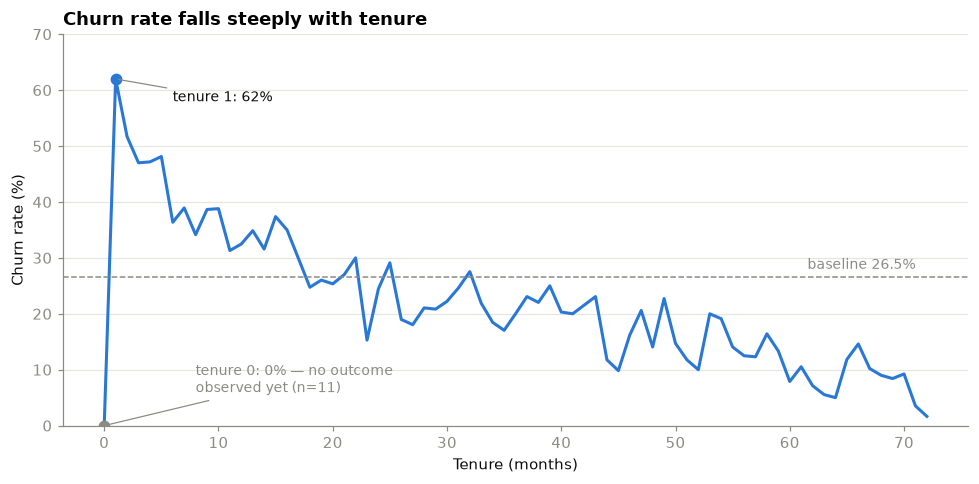

In [7]:
by_tenure = raw_num.groupby("tenure")["Churn"].agg(customers="size", churn_pct=churn_rate)

fig, ax = plt.subplots()
ax.plot(by_tenure.index, by_tenure["churn_pct"], color=BLUE, linewidth=2)
ax.axhline(baseline, color=MUTED, linewidth=1, linestyle="--")
ax.text(71, baseline + 1.5, f"baseline {baseline:.1f}%", color=MUTED, ha="right", fontsize=9)

# Direct-label the two points that matter, rather than every point.
ax.scatter([1], [by_tenure.loc[1, "churn_pct"]], color=BLUE, s=45, zorder=3)
ax.annotate(f"tenure 1: {by_tenure.loc[1, 'churn_pct']:.0f}%",
            xy=(1, by_tenure.loc[1, "churn_pct"]), xytext=(6, 58),
            color=INK, fontsize=9,
            arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8))
ax.scatter([0], [by_tenure.loc[0, "churn_pct"]], color=MUTED, s=45, zorder=3)
ax.annotate("tenure 0: 0% — no outcome\nobserved yet (n=11)",
            xy=(0, 0), xytext=(8, 6), color=MUTED, fontsize=9,
            arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8))

ax.set_title("Churn rate falls steeply with tenure")
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Churn rate (%)")
ax.set_ylim(0, 70)
ax.grid(axis="y")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### Comparing the four treatments

| Option | Verdict |
|---|---|
| **Median-impute (\$1,394.55)** | **Wrong.** Asserts a never-billed customer has paid \$1,394.55. Fabricates data. |
| **Impute `tenure × MonthlyCharges`** | Equals 0 anyway — same answer, extra steps. |
| **Set `TotalCharges = 0`** | **Correct by definition.** Zero months billed = zero charged. Not an estimate. |
| **Drop the rows** | Defensible for modeling — but throws away information during *cleaning*. |

### ✅ Decision 1

**Set `TotalCharges = 0` and keep all 11 rows.** Flag them for possible exclusion in Stage 5.

The cleaning stage should *preserve and correct*; it should not make modeling decisions.

**What could go wrong:** at 11 of 7,043 rows (0.16%) this has no measurable effect on any metric.
The risk is habit-formation — on a dataset where structurally-unlabelled rows are 15% instead of
0.16%, keeping them would corrupt the model. The reasoning transfers even though the row count here
doesn't.

**Are these a meaningful "new customer" segment?** No — they carry no churn signal, so they can
teach a model nothing. The real new-customer segment is `tenure = 1`, at 62% churn. That is a
genuine Stage 4 finding.

---
# Issue 2 — `"No internet service"`

Six service columns have a third value beyond `Yes`/`No`. The common move is to collapse it to
`"No"`. Let's check whether that loses anything.

In [8]:
SERVICES = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
            "TechSupport", "StreamingTV", "StreamingMovies"]

summary = raw.groupby("OnlineSecurity")["Churn"].agg(customers="size", churn_pct=churn_rate).round(1)
summary

,customers,churn_pct
OnlineSecurity,,
No,3498,41.8
No internet service,1526,7.4
Yes,2019,14.6


**7.4% versus 41.8%.** The two groups that a naive collapse would merge are the *lowest-risk* and
the *highest-risk* groups in the dataset — a 34-point gap. Collapsing without care would be a
serious error.

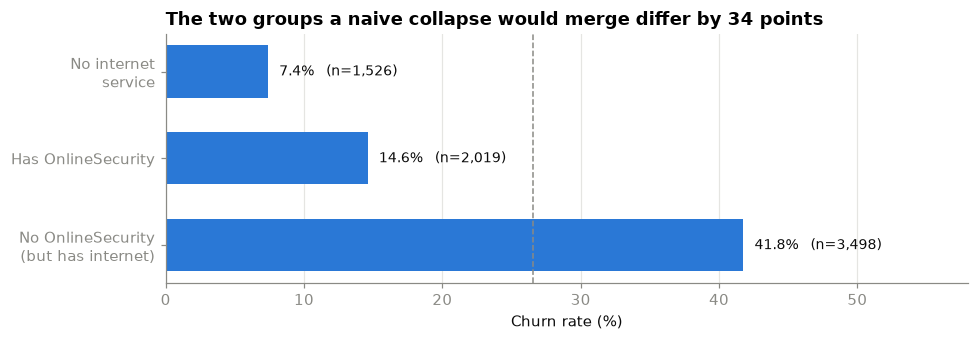

In [9]:
os_rates = raw.groupby("OnlineSecurity")["Churn"].agg(n="size", pct=churn_rate)
order = ["No internet service", "Yes", "No"]
labels = ["No internet\nservice", "Has OnlineSecurity", "No OnlineSecurity\n(but has internet)"]

fig, ax = plt.subplots(figsize=(9, 3.2))
bars = ax.barh(labels, [os_rates.loc[k, "pct"] for k in order], color=BLUE, height=0.6)
for bar, k in zip(bars, order):
    ax.text(bar.get_width() + 0.8, bar.get_y() + bar.get_height() / 2,
            f"{os_rates.loc[k, 'pct']:.1f}%   (n={int(os_rates.loc[k, 'n']):,})",
            va="center", color=INK, fontsize=9)

ax.axvline(baseline, color=MUTED, linewidth=1, linestyle="--")
ax.set_title("The two groups a naive collapse would merge differ by 34 points")
ax.set_xlabel("Churn rate (%)")
ax.set_xlim(0, 58)
ax.invert_yaxis()
ax.grid(axis="x")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### But where does that signal actually live?

Before concluding "keep the three-level column", check whether `"No internet service"` is telling
us anything that `InternetService` doesn't already say.

In [10]:
no_internet = raw["InternetService"] == "No"

print("Is 'No internet service' exactly the same set of customers as InternetService == 'No'?\n")
for col in SERVICES:
    identical = (raw[col] == "No internet service").equals(no_internet)
    n = (raw[col] == "No internet service").sum()
    print(f"  {col:<18} identical: {identical}   (n={n})")

Is 'No internet service' exactly the same set of customers as InternetService == 'No'?

  OnlineSecurity     identical: True   (n=1526)
  OnlineBackup       identical: True   (n=1526)
  DeviceProtection   identical: True   (n=1526)
  TechSupport        identical: True   (n=1526)
  StreamingTV        identical: True   (n=1526)
  StreamingMovies    identical: True   (n=1526)


**Identical in all six columns — the same 1,526 people, six times over.**

This is worse than redundant. One-hot encoding produces six dummy columns that are bit-for-bit
identical to `InternetService_No`: **seven duplicate columns in the design matrix**. That is perfect
multicollinearity. Logistic regression coefficients then split arbitrarily among the duplicates and
cannot be interpreted at all.

Let's confirm the duplication is literal:

In [11]:
# Build the dummies the way a modeling pipeline would, and look for duplicate columns.
dummies = pd.get_dummies(raw[["InternetService"] + SERVICES], dtype=int)
target = dummies["InternetService_No"]
duplicates = [c for c in dummies.columns if c != "InternetService_No" and dummies[c].equals(target)]

print("Columns bit-for-bit identical to InternetService_No:")
for dup in duplicates:
    print("  ", dup)
print(f"\n=> {len(duplicates) + 1} identical columns in the design matrix.")

Columns bit-for-bit identical to InternetService_No:
   OnlineSecurity_No internet service
   OnlineBackup_No internet service
   DeviceProtection_No internet service
   TechSupport_No internet service
   StreamingTV_No internet service
   StreamingMovies_No internet service

=> 7 identical columns in the design matrix.


Now the same question for `MultipleLines`, where the answer turns out to be different:

In [12]:
ml = raw.groupby("MultipleLines")["Churn"].agg(customers="size", churn_pct=churn_rate).round(1)
print(ml.to_string())
print()
print("'No phone service' == PhoneService == 'No' :",
      (raw["MultipleLines"] == "No phone service").equals(raw["PhoneService"] == "No"))

                  customers  churn_pct
MultipleLines                         
No                     3390       25.0
No phone service        682       24.9
Yes                    2971       28.6

'No phone service' == PhoneService == 'No' : True


Here `"No phone service"` (24.9%) and plain `"No"` (25.0%) are **0.1 points apart** — collapsing
costs essentially nothing, and the category is again identical to `PhoneService == "No"`.

### ✅ Decision 2

**Keep the original three levels in the cleaned file. Handle the redundancy in the Stage 5
preprocessing pipeline.**

The redundancy is real and the collinearity it causes is real — the evidence above is not in doubt.
But *how to encode a column for a model* is a *modeling* decision, not a data-quality one. Nothing
about `"No internet service"` is **wrong**; it is merely inconvenient for one family of models.

The rule this notebook follows: **the cleaning stage fixes what is incorrect, and changes nothing
else.** Collapsing here would bake one modeling choice into the file every later stage reads, and
would quietly discard a distinction (7.4% vs 41.8% churn) that aggregation and EDA can use
directly without any encoding at all.

Deferring keeps the option open and testable. In Stage 5 we can compare, inside a pipeline fitted on
training data only:

1. collapse to `"No"` and rely on `InternetService` to carry the effect
2. keep three levels and drop the redundant dummy column after encoding
3. keep three levels as-is and let a regularised model or a tree absorb it

**What we carry forward:** the six service columns and `MultipleLines` each contain a level that is
bit-identical to `InternetService == "No"` / `PhoneService == "No"`. One-hot encoding them naively
will produce seven duplicate columns. Stage 5 must handle this — it is now recorded, not solved.

---
# Issue 3 — `SeniorCitizen` is coded `0/1`

Every other binary column uses `Yes`/`No`. Is that inconsistency an actual problem, or just untidy?

In [13]:
sc = raw.groupby("SeniorCitizen")["Churn"].agg(customers="size", churn_pct=churn_rate).round(1)
print(sc.to_string())
print(f"\nSeniors churn at {sc.loc['1', 'churn_pct'] / sc.loc['0', 'churn_pct']:.1f}x the rate "
      "of non-seniors -- a real finding for Stage 4.\n")

print("Other binary columns for comparison:")
for col in ["Partner", "Dependents", "PhoneService", "PaperlessBilling"]:
    print(f"  {col:<18} {sorted(raw[col].unique())}")

               customers  churn_pct
SeniorCitizen                      
0                   5901       23.6
1                   1142       41.7

Seniors churn at 1.8x the rate of non-seniors -- a real finding for Stage 4.

Other binary columns for comparison:
  Partner            ['No', 'Yes']
  Dependents         ['No', 'Yes']
  PhoneService       ['No', 'Yes']
  PaperlessBilling   ['No', 'Yes']


On its own, `0/1` is **not** a modeling problem — it is exactly the format every `Yes`/`No` column
has to be converted *to* before modeling. It is the most model-ready column in the file.

**But here is the concrete bug it causes.** In Stage 5 we route columns to numeric vs. categorical
preprocessing, and the standard way to do that is by dtype:

In [14]:
from sklearn.preprocessing import StandardScaler

# Simulate what a Stage 5 pipeline does if SeniorCitizen is left as an integer.
demo = raw[["SeniorCitizen", "tenure", "MonthlyCharges", "Partner"]].copy()
demo["SeniorCitizen"] = demo["SeniorCitizen"].astype(int)
for col in ["tenure", "MonthlyCharges"]:
    demo[col] = pd.to_numeric(demo[col])

numeric_cols = demo.select_dtypes(include="number").columns.tolist()
print("Columns auto-selected as 'numeric':", numeric_cols)
print("  -> SeniorCitizen got swept in with tenure and MonthlyCharges.\n")

scaled = StandardScaler().fit_transform(demo[numeric_cols])
print("SeniorCitizen after StandardScaler:", np.unique(scaled[:, 0]).round(2))
print("  -> 0/1 became -0.44/+2.27. The coefficient now means 'per standard deviation")
print("     of senior-ness', which is not interpretable.")

Columns auto-selected as 'numeric': ['SeniorCitizen', 'tenure', 'MonthlyCharges']
  -> SeniorCitizen got swept in with tenure and MonthlyCharges.

SeniorCitizen after StandardScaler: [-0.44  2.27]
  -> 0/1 became -0.44/+2.27. The coefficient now means 'per standard deviation
     of senior-ness', which is not interpretable.


### ✅ Decision 3

**Keep the original `0`/`1` coding. Handle the routing problem in the Stage 5 pipeline.**

As established above, `0/1` is not *wrong* — it is already the encoding every `Yes`/`No` column must
be converted to before modeling. Recoding it would be changing correct data to suit a downstream
convenience, which is exactly what a cleaning script should not do.

The scaler bug demonstrated above is a genuine hazard, but it is a hazard of **dtype-based column
routing**, not of the data. The fix belongs where the bug lives:

```python
# Stage 5: name the columns explicitly instead of inferring them from dtype.
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = [c for c in X.columns if c not in numeric_features]
```

Explicit column lists are more robust than `select_dtypes` anyway — they fail loudly when a column
is added or renamed, instead of silently re-routing it.

**Final encoding:** `0`/`1` in `telco_clean.csv`, treated as a categorical feature in the Stage 5
pipeline by explicit naming.

---
# Issue 4 — `TotalCharges` vs `tenure × MonthlyCharges`

It is widely repeated that `TotalCharges ≈ tenure × MonthlyCharges`. Let's verify rather than assume.

In [15]:
# `charges` is a SUBSET built for this section only: the 11 blank-TotalCharges rows
# are excluded so the correlation maths has no NaNs. This is an analysis convenience,
# NOT the cleaning decision -- that was to keep all 11 rows and set them to 0.0.
charges = raw_num.dropna(subset=["TotalCharges"]).copy()
charges["implied"] = charges["tenure"] * charges["MonthlyCharges"]

print(f"charges: {len(charges)} rows  (raw has {len(raw)}; 11 excluded for this section)")

pairs = [("TotalCharges", "implied"), ("TotalCharges", "tenure"),
         ("TotalCharges", "MonthlyCharges"), ("tenure", "MonthlyCharges")]
for a, b in pairs:
    name = "tenure x MonthlyCharges" if b == "implied" else b
    print(f"  corr({a}, {name})".ljust(50), f"= {charges[a].corr(charges[b]):.4f}")

charges: 7032 rows  (raw has 7043; 11 excluded for this section)
  corr(TotalCharges, tenure x MonthlyCharges)      = 0.9996
  corr(TotalCharges, tenure)                       = 0.8259
  corr(TotalCharges, MonthlyCharges)               = 0.6511
  corr(tenure, MonthlyCharges)                     = 0.2469


A correlation of 0.9996 — but *not* 1.0. The gap is the interesting part.

In [16]:
charges["residual"] = charges["TotalCharges"] - charges["implied"]
charges["abs_pct_err"] = (charges["residual"] / charges["TotalCharges"]).abs() * 100

print("Residual: TotalCharges - (tenure x MonthlyCharges)")
print(charges["residual"].describe().round(2).to_string())
print()
print("Absolute percentage error")
print(charges["abs_pct_err"].describe(percentiles=[.5, .9, .99]).round(2).to_string())
print()
print(f"within 1% of the product : {(charges['abs_pct_err'] <= 1).mean():.1%}")
print(f"within 5% of the product : {(charges['abs_pct_err'] <= 5).mean():.1%}")

Residual: TotalCharges - (tenure x MonthlyCharges)
count    7032.00
mean        0.15
std        67.26
min      -370.85
25%       -28.65
50%         0.00
75%        28.70
max       373.25

Absolute percentage error
count    7032.00
mean        3.21
std         4.00
min         0.00
50%         2.00
90%         7.52
99%        19.94
max        45.06

within 1% of the product : 30.7%
within 5% of the product : 80.5%


**Why it isn't exact:** `MonthlyCharges` is the customer's *current* rate, while `TotalCharges`
accumulated across a history in which they may have added services, dropped them, or seen a price
change.

So the residual is **not noise — it is a record of how a customer's spending has drifted over their
lifetime.** A customer at +\$370 has been downgrading; one at −\$370 has been upgrading. That is
potentially real signal, and a candidate engineered feature for Stage 5.

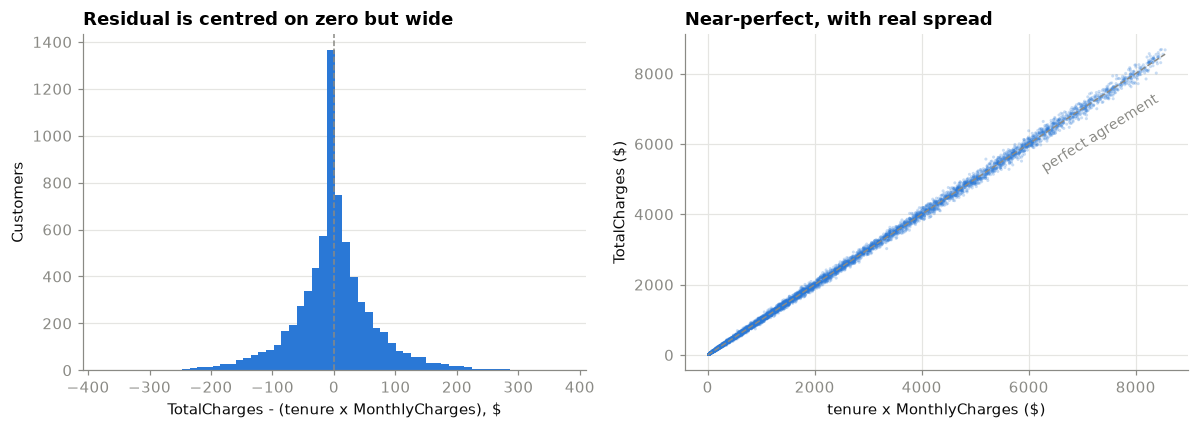

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.hist(charges["residual"], bins=60, color=BLUE)
ax1.axvline(0, color=MUTED, linewidth=1, linestyle="--")
ax1.set_title("Residual is centred on zero but wide")
ax1.set_xlabel("TotalCharges - (tenure x MonthlyCharges), $")
ax1.set_ylabel("Customers")
ax1.grid(axis="y"); ax1.set_axisbelow(True)

ax2.scatter(charges["implied"], charges["TotalCharges"], s=4, alpha=0.25,
            color=BLUE, edgecolors="none")
lim = [0, charges["implied"].max()]
ax2.plot(lim, lim, color=MUTED, linewidth=1, linestyle="--")
ax2.text(6200, 5200, "perfect agreement", color=MUTED, fontsize=9, rotation=32)
ax2.set_title("Near-perfect, with real spread")
ax2.set_xlabel("tenure x MonthlyCharges ($)")
ax2.set_ylabel("TotalCharges ($)")
ax2.grid(); ax2.set_axisbelow(True)

plt.tight_layout()
plt.show()

### How bad is the multicollinearity?

The standard measure is the **Variance Inflation Factor**. Regress `TotalCharges` on the other two
numeric features and compute `VIF = 1 / (1 - R²)`.

In [18]:
X = np.column_stack([np.ones(len(charges)), charges["tenure"], charges["MonthlyCharges"]])
y = charges["TotalCharges"].to_numpy()

beta, *_ = np.linalg.lstsq(X, y, rcond=None)
pred = X @ beta
r2 = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()
vif = 1 / (1 - r2)

print("TotalCharges ~ tenure + MonthlyCharges")
print(f"  intercept       {beta[0]:9.2f}")
print(f"  tenure          {beta[1]:9.2f}")
print(f"  MonthlyCharges  {beta[2]:9.2f}")
print(f"\n  R^2 = {r2:.4f}   ->   VIF = {vif:.1f}")
print(f"\n  Standard errors on these coefficients are inflated by ~sqrt(VIF) = {np.sqrt(vif):.1f}x")

TotalCharges ~ tenure + MonthlyCharges
  intercept        -2162.43
  tenure              65.41
  MonthlyCharges      35.88

  R^2 = 0.8950   ->   VIF = 9.5

  Standard errors on these coefficients are inflated by ~sqrt(VIF) = 3.1x


**VIF = 9.5**, right at the conventional danger threshold of 10.

### Why this matters for logistic regression but not for trees

**Logistic regression** solves for all coefficients *simultaneously*. When `TotalCharges` is 89%
explained by the other two features, many different coefficient combinations fit almost equally well
— the model can raise `TotalCharges` and lower `tenure` to compensate with nearly no loss. The
consequences:

- standard errors inflate by roughly **3.1×**
- a coefficient can **flip sign** relative to that feature's own standalone association with churn
- at smaller sample sizes, coefficients become **unstable across splits**

Critically: **predictions stay fine; interpretation breaks.** Since half the reason we are using
logistic regression is interpretability, that is precisely the wrong thing to break.

**Tree-based models** evaluate one split on one variable at a time. If two features are nearly
interchangeable, the tree picks whichever splits marginally better and moves on — accuracy is
unaffected. The side effect is different: **feature importance gets diluted** across the correlated
group, so each looks moderately important when the underlying signal is really one strong concept.

Rather than take that on faith, let's fit the same feature on its own and then alongside its
collinear partners, and watch what happens to its coefficient.

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# NOTE: a diagnostic to expose collinearity, NOT our Stage 5 model.
# C=np.inf means no regularisation, so we see the raw, unpenalised coefficients.
yd = (charges["Churn"] == "Yes").astype(int).to_numpy()

def coefs_for(features):
    X = StandardScaler().fit_transform(charges[features].to_numpy())
    model = LogisticRegression(max_iter=2000, C=np.inf).fit(X, yd)
    return dict(zip(features, model.coef_[0].round(3)))

print("TotalCharges on its own      :", coefs_for(["TotalCharges"]))
print("tenure on its own            :", coefs_for(["tenure"]))
print("tenure + MonthlyCharges      :", coefs_for(["tenure", "MonthlyCharges"]))
print("all three together           :", coefs_for(["tenure", "MonthlyCharges", "TotalCharges"]))

TotalCharges on its own      : {'TotalCharges': np.float64(-0.536)}
tenure on its own            : {'tenure': np.float64(-0.957)}
tenure + MonthlyCharges      : {'tenure': np.float64(-1.351), 'MonthlyCharges': np.float64(0.99)}
all three together           : {'tenure': np.float64(-1.647), 'MonthlyCharges': np.float64(0.908), 'TotalCharges': np.float64(0.329)}


**There it is — a sign flip on real data.**

`TotalCharges` on its own has a coefficient of **−0.53**: customers who have spent more in total are
*less* likely to churn. That matches intuition, since high total spend mostly means long tenure.

Add `tenure` and `MonthlyCharges` to the model and that coefficient becomes **+0.31** — the sign
reverses. Read naively, the full model appears to say "higher total spend increases churn risk."

Both numbers are *arithmetically* correct. The second one is conditional: *holding tenure and
monthly rate fixed*, a higher accumulated total implies the customer used to pay more than they do
now — a downgrader. But nobody reads a coefficient table that carefully, and this is exactly how
collinearity produces confidently-stated nonsense.

Notice too that `tenure`'s coefficient inflates from −0.95 alone to −1.63 in the full model. The two
features are partly cancelling each other out.

### Does this also destabilise the coefficients?

At full sample size, barely — so let's be accurate about that rather than overclaim. The effect of
collinearity depends on how much data you have:

In [20]:
feats = ["tenure", "MonthlyCharges", "TotalCharges"]

# Each "sample" is a random 80% subset, so the five fits really do see different data.
# (Sampling ALL the rows without replacement would return the identical set every time
#  and would show zero spread for trivial reasons -- a tempting but meaningless result.)
for n in [400, 2000, int(0.8 * len(charges))]:
    rows = []
    for seed in range(5):
        idx = np.random.RandomState(seed).choice(len(charges), n, replace=False)
        X = StandardScaler().fit_transform(charges[feats].to_numpy()[idx])
        model = LogisticRegression(max_iter=2000, C=np.inf).fit(X, yd[idx])
        rows.append(dict(zip(feats, model.coef_[0].round(2))))
    table = pd.DataFrame(rows, index=[f"sample {i}" for i in range(5)])
    print(f"n = {n}")
    print(table.to_string())
    print("  spread (max - min):", (table.max() - table.min()).round(2).to_dict(), "\n")

n = 400
          tenure  MonthlyCharges  TotalCharges
sample 0   -1.44            0.96          0.04
sample 1   -1.35            0.88          0.24
sample 2   -2.08            0.69          0.82
sample 3   -1.59            0.98          0.13
sample 4   -1.57            1.00          0.33
  spread (max - min): {'tenure': 0.73, 'MonthlyCharges': 0.31, 'TotalCharges': 0.78} 

n = 2000
          tenure  MonthlyCharges  TotalCharges
sample 0   -1.64            0.91          0.35
sample 1   -1.70            0.86          0.40
sample 2   -1.90            0.73          0.68
sample 3   -1.60            0.89          0.26
sample 4   -1.53            0.95          0.20
  spread (max - min): {'tenure': 0.37, 'MonthlyCharges': 0.22, 'TotalCharges': 0.48} 

n = 5625
          tenure  MonthlyCharges  TotalCharges
sample 0   -1.75            0.88          0.41
sample 1   -1.57            0.94          0.22
sample 2   -1.74            0.90          0.42
sample 3   -1.70            0.87          0.39
s

The spread shrinks steadily as the sample grows — for `TotalCharges`, roughly **0.78 → 0.48 → 0.20**.

At n = 400 that coefficient lands anywhere from 0.04 to 0.82, a twentyfold relative swing: with a
small sample you could run this analysis twice and tell two different stories. At full size it
settles down.

So the honest conclusion is **narrower than the textbook warning**. At our sample size, VIF = 9.5
does two things: it inflates standard errors, and it **reverses the sign of `TotalCharges`** relative
to that feature's own association with churn. What it does *not* do here is make the fit jump around
between splits — we have enough data to pin the coefficients down.

That distinction is worth internalising. "High VIF" is not a single failure mode, and the part of it
that bites depends on how much data you have. Reporting the sign flip is honest; claiming the model
is unstable when the evidence shows it isn't would not be.

### ✅ Decision 4

**Keep `TotalCharges` in the cleaned data.**

There is no *data-quality* reason to remove it — it is a genuine, correctly-recorded field. Dropping
it would be a **modeling** decision, and modeling decisions do not belong in a cleaning script.

Flagged for Stage 5, where we will compare three options:
1. keep all three features
2. drop `TotalCharges`
3. replace it with the residual (`spending drift`) as an engineered feature

---
# Summary of decisions

| # | Issue | Decision | Type |
|---|---|---|---|
| 1 | 11 `tenure = 0` rows | `TotalCharges = 0`, keep rows, flag for Stage 5 | Factual correction |
| 2 | `"No internet service"` | **Keep** all three levels. Collinearity handled in Stage 5 | Not a cleaning decision |
| 3 | `SeniorCitizen` `0/1` | **Keep** `0/1`. Route columns explicitly in Stage 5 | Not a cleaning decision |
| 4 | `TotalCharges` collinearity | **Keep.** Decide in Stage 5 | Not a cleaning decision |

Plus: strip whitespace from all text columns, convert `tenure` to integer and the two charge columns
to float.

**Only one of the four issues turned out to be a cleaning problem.** The other three are real, and
the evidence for them above is solid — but they are questions about how to *represent* the data for
a model, not about whether the data is *correct*. The cleaned file fixes what was wrong and changes
nothing else, which keeps all three decisions open, reversible and testable in Stage 5.

### What is deliberately *not* done during cleaning

Nothing here is **fitted** to the data. Every change is a *fact about* the data, not a *parameter
estimated from* it.

Encoding, category collapsing, scaling, imputation, feature selection and row exclusion all wait for
the Stage 5 pipeline, **fitted on the training split only**. Fitting any of them across all 7,043 rows would leak
test-set information into the model and produce optimistically biased scores.

---
# Verifying the output

These decisions are implemented in `src/clean_data.py`. Let's run it and check the result.

In [21]:
import subprocess, sys

result = subprocess.run([sys.executable, str(ROOT / "src" / "clean_data.py")],
                        capture_output=True, text=True, cwd=ROOT)
print(result.stdout or result.stderr)

Read   data/raw/telco_customer_churn.csv  (7043 rows)
Wrote  data/processed/telco_clean.csv  (7043 rows, 21 columns)

Changes applied:
  TotalCharges : 11 blank values -> 0.0 (verified: all have tenure == 0)
  dtypes       : tenure -> int64, MonthlyCharges/TotalCharges -> float64
  whitespace   : stripped from all text columns

Left unchanged (representation choices -> Stage 5 pipeline):
  'No internet service' kept in 6 columns (1526 customers)
  'No phone service'    kept in MultipleLines (682 customers)
  SeniorCitizen kept as 0/1

Not done here (belongs in the Stage 5 pipeline, fitted on training data
only, to avoid leakage): encoding, scaling, imputation, feature selection,
category collapsing, row exclusion

Rows dropped   : 0
Churn rate     : 26.54%  (unchanged from raw -- cleaning must not move the target)

NOTE for Stage 5: the 11 customers with tenure == 0 have no observed
outcome yet -- no customer with tenure 0 can be labelled Churn=Yes. Their
'No' is definitional, not meas

In [22]:
clean = pd.read_csv(ROOT / "data" / "processed" / "telco_clean.csv")

checks = {
    "row count unchanged (7043)":        len(clean) == 7043,
    "no missing values":                 clean.isna().sum().sum() == 0,
    "churn rate unchanged":              abs(churn_rate(clean["Churn"]) - baseline) < 1e-9,
    "tenure=0 rows have TotalCharges 0": (clean.loc[clean["tenure"] == 0, "TotalCharges"] == 0).all(),
    "service columns keep 3 levels":     all(set(clean[c].unique()) ==
                                             {"Yes", "No", "No internet service"} for c in SERVICES),
    "MultipleLines keeps 3 levels":      set(clean["MultipleLines"].unique()) ==
                                         {"Yes", "No", "No phone service"},
    "SeniorCitizen still 0/1":           set(clean["SeniorCitizen"].unique()) == {0, 1},
    "tenure is an integer column":       clean["tenure"].dtype.kind == "i",
    "customerID still unique":           clean["customerID"].is_unique,
}
for label, ok in checks.items():
    print(f"  {'PASS' if ok else 'FAIL'}  {label}")

assert all(checks.values()), "A post-cleaning check failed"
print("\nAll checks passed.")
clean.head()

  PASS  row count unchanged (7043)
  PASS  no missing values
  PASS  churn rate unchanged
  PASS  tenure=0 rows have TotalCharges 0
  PASS  service columns keep 3 levels
  PASS  MultipleLines keeps 3 levels
  PASS  SeniorCitizen still 0/1
  PASS  tenure is an integer column
  PASS  customerID still unique

All checks passed.


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


---
### Next: Stage 3 — Exploratory data analysis

Answer *who is churning* and *what is churn associated with*, using the cleaned file.

Open questions carried forward:

- **Fiber-optic customers churn at 41.9%, DSL at 19.0%** — despite fiber being the premium product. Why?
- **Electronic check churns at 45.3%**, while both *automatic* payment methods sit near 15–17%. Is the
  real driver *automatic vs. manual*, rather than the specific instrument?
- **`tenure = 1` churns at 62%.** What distinguishes the new customers who stay from those who leave?
- **`gender` shows a 0.7-point gap** — a useful negative result worth reporting, not hiding.